In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")    
plt.rcParams['figure.figsize'] = (12, 6)



In [4]:
df = pd.read_csv("student_performance_informatika.csv")

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   attendance_pct       800 non-null    float64
 1   study_hours_week     800 non-null    float64
 2   sleep_hours          800 non-null    float64
 3   screen_time_hours    800 non-null    float64
 4   parttime_hours_week  800 non-null    int64  
 5   commute_minutes      800 non-null    int64  
 6   internet_quality     800 non-null    int64  
 7   org_activity         800 non-null    int64  
 8   hs_math_score        800 non-null    int64  
 9   assignment_avg       800 non-null    float64
 10  quiz_avg             800 non-null    float64
 11  midterm_score        800 non-null    float64
 12  Year                 800 non-null    int64  
 13  passed               800 non-null    int64  
dtypes: float64(7), int64(7)
memory usage: 87.6 KB


In [6]:
df.shape

(800, 14)

In [7]:
df.head()

,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year,passed
0,75.2,8.9,6.8,1.0,0,28,4,2,82,74.0,63.5,76.6,2024,1
1,74.3,6.7,4.2,1.7,0,37,3,0,100,64.2,62.4,63.1,2024,1
2,84.1,11.9,7.7,2.2,0,13,4,2,72,73.2,71.1,41.3,2024,1
3,74.4,4.8,6.6,3.7,6,15,3,1,61,42.3,49.5,76.0,2024,0
4,100.0,7.5,6.4,2.2,0,30,4,2,70,66.7,51.9,71.4,2024,1


In [8]:
df.tail()

,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year,passed
795,71.6,5.9,8.8,2.0,0,10,3,1,73,59.8,45.8,72.4,2018,0
796,81.8,4.3,7.1,6.5,0,8,3,1,54,43.7,36.2,55.7,2018,0
797,94.5,6.4,6.0,5.8,11,24,4,1,66,64.4,60.5,71.2,2018,1
798,85.0,2.2,6.1,3.8,0,23,3,0,75,68.6,69.2,80.9,2018,1
799,79.9,4.4,7.2,4.3,0,31,2,1,73,58.7,39.4,65.3,2018,0


In [9]:
df.isnull().sum()

attendance_pct         0
study_hours_week       0
sleep_hours            0
screen_time_hours      0
parttime_hours_week    0
commute_minutes        0
internet_quality       0
org_activity           0
hs_math_score          0
assignment_avg         0
quiz_avg               0
midterm_score          0
Year                   0
passed                 0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year,passed
count,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,84.613250,6.554125,6.396875,4.055750,5.090000,30.398750,3.312500,0.903750,72.720000,67.740875,61.692750,64.377625,2020.921250,0.575000
std,10.269008,3.871608,1.086798,2.159977,8.785977,19.174249,0.931896,0.907202,11.293517,10.635872,12.265017,11.432477,2.074953,0.494652
min,54.800000,0.800000,3.400000,1.000000,0.000000,2.000000,1.000000,0.000000,35.000000,40.300000,23.900000,32.600000,2018.000000,0.000000
25%,77.250000,3.700000,5.600000,2.400000,0.000000,17.000000,3.000000,0.000000,65.000000,60.100000,53.600000,56.400000,2019.000000,0.000000
50%,84.700000,5.750000,6.400000,3.700000,0.000000,26.000000,3.000000,1.000000,73.000000,67.400000,61.650000,64.750000,2021.000000,1.000000
75%,92.800000,8.325000,7.100000,5.300000,8.250000,40.000000,4.000000,1.000000,80.000000,74.325000,69.725000,71.725000,2023.000000,1.000000
max,100.000000,21.900000,9.900000,13.500000,29.000000,136.000000,5.000000,3.000000,100.000000,100.000000,100.000000,97.000000,2024.000000,1.000000


In [19]:
num_cols = df.columns.to_list()

In [34]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1 
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 *  IQR

    
    df[col] = np.where(df[col] < lower_bound , lower_bound,
              np.where(df[col] > upper_bound, upper_bound, df[col]))

    print(f"""COLOMNS : {col}
            Q1 : {Q1}
            Q3 : {Q3}
            IQR : {IQR}
        LOWER BOUND : {lower_bound}
        UPPER BOUND : {upper_bound}
    """)





COLOMNS : attendance_pct
            Q1 : 77.25
            Q3 : 92.8
            IQR : 15.549999999999997
        LOWER BOUND : 53.925000000000004
        UPPER BOUND : 116.125
    
COLOMNS : study_hours_week
            Q1 : 3.7
            Q3 : 8.325000000000001
            IQR : 4.625000000000001
        LOWER BOUND : -3.2375000000000016
        UPPER BOUND : 15.262500000000003
    
COLOMNS : sleep_hours
            Q1 : 5.6
            Q3 : 7.1
            IQR : 1.5
        LOWER BOUND : 3.3499999999999996
        UPPER BOUND : 9.35
    
COLOMNS : screen_time_hours
            Q1 : 2.4
            Q3 : 5.3
            IQR : 2.9
        LOWER BOUND : -1.9499999999999997
        UPPER BOUND : 9.649999999999999
    
COLOMNS : parttime_hours_week
            Q1 : 0.0
            Q3 : 8.25
            IQR : 8.25
        LOWER BOUND : -12.375
        UPPER BOUND : 20.625
    
COLOMNS : commute_minutes
            Q1 : 17.0
            Q3 : 40.0
            IQR : 23.0
        LOWER BOUND

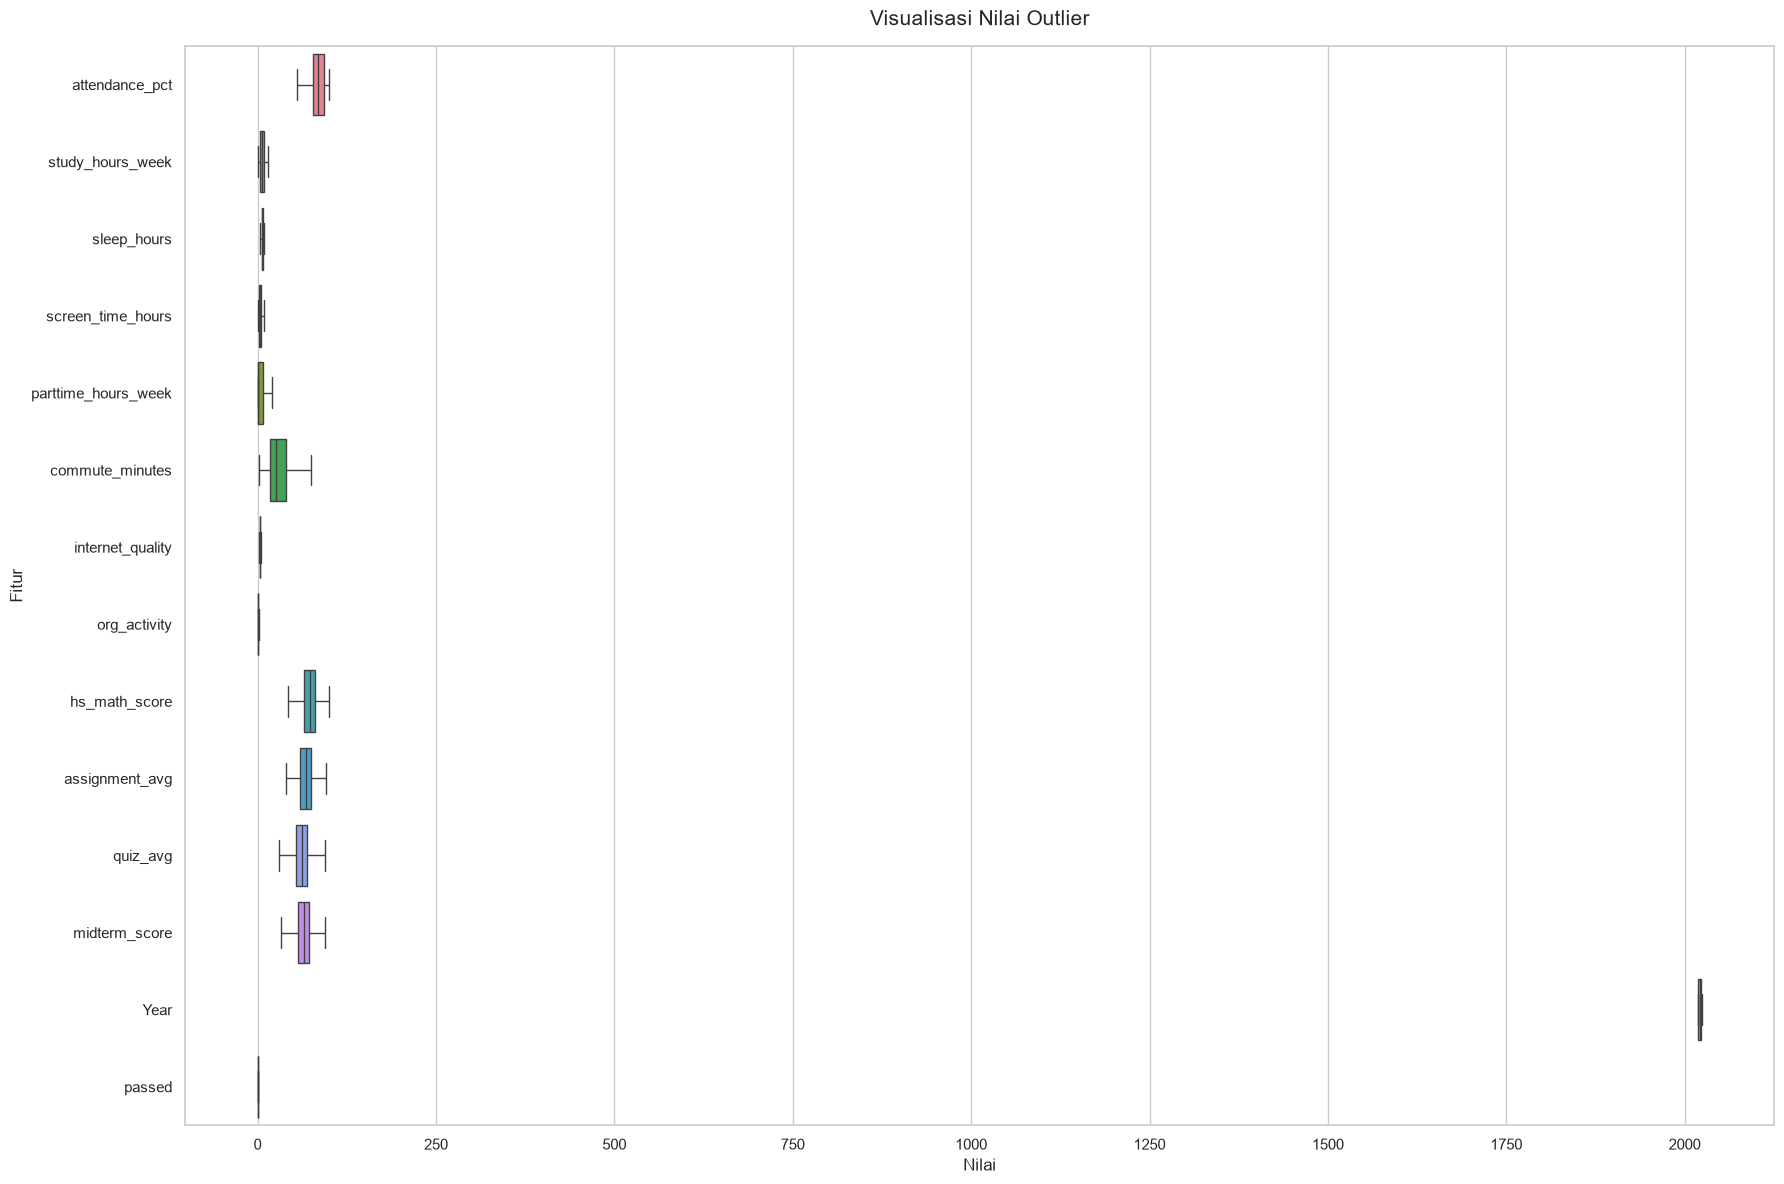

BERIKUT DATA OUTLIER SETELAH DI BUAT LEBIH RAPIH (AFTER DI CAPPING)


In [37]:
data = num_cols
plt.figure(figsize=(18,12))
sns.boxplot(data=df[data], orient='h')
plt.title("Visualisasi Nilai Outlier", fontsize=15, pad=15)
plt.xlabel("Nilai" , fontsize=12)
plt.ylabel("Fitur", fontsize=12)

plt.tight_layout()
plt.show()

print("berikut data outlier setelah di buat lebih rapih (after di capping)".upper())